1 — Import Library

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

2 — Import Dataset

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

df = pd.read_excel("dataset_validasi_pakar.xlsx",sheet_name="Validasi Pakar")
df.head()

Saving dataset_validasi_pakar.xlsx to dataset_validasi_pakar.xlsx


,No,Komentar,Label Awal,Label Pakar,Pasal Dominan,Catatan,Unnamed: 6
0,1,anu boga modal mah bulak balik jadi anggota dp...,Kritik atau opini negatif,Kritik atau opini negatif,NaN,Tidak terindikasi Pasal 27A maupun Pasal 28 ay...,NaN
1,2,Para pejabat seperti ini yg dipelihara di nega...,Kritik atau opini negatif,Kritik atau opini negatif,NaN,Tidak terindikasi Pasal 27A maupun Pasal 28 ay...,NaN
2,3,Sepaham kita,Netral atau tidak terindikasi,NaN,NaN,NaN,NaN
3,4,kasus klasik. Pejabat suku jawa bersatu padu m...,Kritik atau opini negatif,Kritik atau opini negatif,NaN,Tidak terindikasi Pasal 27A maupun Pasal 28 ay...,NaN
4,5,"Kalo di olahraga kaderisasinya jelas, ada anak...",Konten ofensif,Kritik atau opini negatif,NaN,Tidak terindikasi Pasal 27A maupun Pasal 28 ay...,NaN


3 — Melihat Struktur Dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   No             8000 non-null   int64 
 1   Komentar       8000 non-null   object
 2   Label Awal     8000 non-null   object
 3   Label Pakar    7997 non-null   object
 4   Pasal Dominan  642 non-null    object
 5   Catatan        6994 non-null   object
 6   Unnamed: 6     2 non-null      object
dtypes: int64(1), object(6)
memory usage: 437.6+ KB


In [ ]:
df.shape

(8000, 7)

In [ ]:
df.columns

Index(['No', 'Komentar', 'Label Awal', 'Label Pakar', 'Pasal Dominan',
       'Catatan', 'Unnamed: 6'],
      dtype='object')

4 - Missing Value

In [ ]:
df.isnull().sum()

,0
No,0
Komentar,0
Label Awal,0
Label Pakar,3
Pasal Dominan,7358
Catatan,1006
Unnamed: 6,7998


5 — Mapping Label Pakar

In [ ]:
# TIDAK DI RUN (KALAU MAU RUN ULANG UNTUK RAPIHKAN BISA DI RUN, UNTUK GANTI CELL DI MAPPING DI BAWAHNYA)

mapping_label = {
    "Netral atau tidak terindikasi": "C0",
    "Kritik atau opini negatif": "C1",
    "Konten ofensif": "C2",
    "Indikasi penghinaan atau kebencian terhadap individu atau kelompok": "C3",
    "Ambigu atau konteks tidak cukup": "C4"
}

df["Kode Label"] = df["Label Pakar"].map(mapping_label)

display(
    df[["Label Pakar", "Kode Label"]]
    .drop_duplicates()
    .sort_values("Kode Label"))

,Label Pakar,Kode Label
7,Netral atau tidak terindikasi,C0
0,Kritik atau opini negatif,C1
6,Konten ofensif,C2
19,Indikasi penghinaan atau kebencian terhadap in...,C3
5,Ambigu atau konteks tidak cukup,C4
2,NaN,NaN


In [ ]:
label_mapping = {
    "Netral atau tidak terindikasi": "C0",
    "Kritik atau opini negatif": "C1",
    "Konten ofensif": "C2",
    "Indikasi penghinaan atau kebencian terhadap individu atau kelompok": "C3",
    "Ambigu atau konteks tidak cukup": "C4"
}

In [ ]:
df["Kode Label"] = df["Label Pakar"].map(label_mapping)
df[["Label Pakar","Kode Label"]].head()

,Label Pakar,Kode Label
0,Kritik atau opini negatif,C1
1,Kritik atau opini negatif,C1
2,NaN,NaN
3,Kritik atau opini negatif,C1
4,Kritik atau opini negatif,C1


6 — Validasi Mapping Label

In [ ]:
df[df["Kode Label"].isnull()]["Label Pakar"].unique()

array([nan], dtype=object)

7 — Distribusi Label C0-C4

In [ ]:
label_distribution = (
    df["Kode Label"]
    .value_counts()
    .sort_index())

label_distribution

,count
Kode Label,
C0,2226
C1,3012
C2,1451
C3,763
C4,545


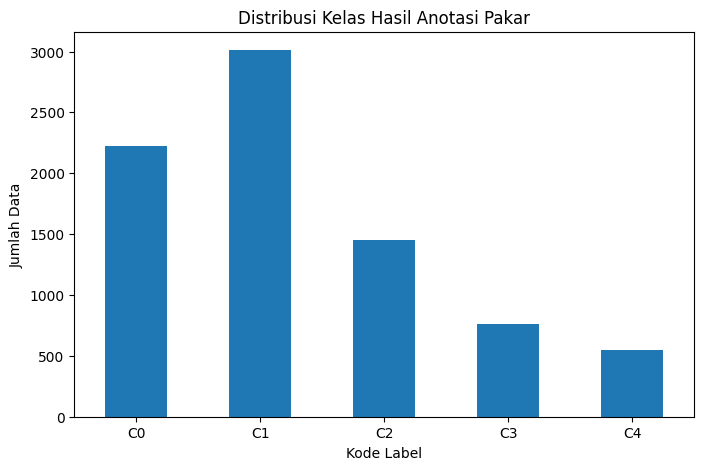

In [ ]:
plt.figure(figsize=(8,5))
label_distribution.plot(kind="bar")

plt.title("Distribusi Kelas Hasil Anotasi Pakar")
plt.xlabel("Kode Label")
plt.ylabel("Jumlah Data")

plt.xticks(rotation=0)
plt.show()

8 — Persentase Distribusi Kelas

In [ ]:
percentage = (
    df["Kode Label"]
    .value_counts(normalize=True)
    .sort_index()*100)

percentage

,proportion
Kode Label,
C0,27.835438
C1,37.664124
C2,18.144304
C3,9.541078
C4,6.815056


9 — Contoh Data Setiap Kelas

In [ ]:
for label in sorted(df["Kode Label"].dropna().unique()):
    print("="*80)
    print("KELAS:", label)

    display(
        df[df["Kode Label"] == label]
        [["Komentar", "Catatan"]].sample(5,random_state=42))

KELAS: C0


,Komentar,Catatan
254,"Bagi Purbaya Jangankan Gibran, dengan Prabowo ...",Tidak terindikasi Pasal 27A maupun Pasal 28 ay...
1578,"ganti nama aja pah jangan DPR, ganti DMP aja (...",NaN
7150,"Ya,betul sekali.Sudah ada sosok bermutu yg dpt...",Dukungan terhadap calon politik berkualitas.
986,iye..iyee...pak bijak,Tidak terindikasi Pasal 27A maupun Pasal 28 ay...
2137,Ya Allah ya Rabb lindungilah para Satria pahla...,makna kalimatnya belum cukup jelas karena tida...


KELAS: C1


,Komentar,Catatan
1131,Pelajaran buat kita warga Indonesia…. Jangan p...,NaN
6278,Ntar kalo ada kejadian aneh2 lg baru dah pada ...,Kritik terhadap standar seleksi aparat
1124,@Meong-x1n Pasukan Kusus apa orang cuman ju...,NaN
143,Para buzzer juga ikut menikmati 😂😂,Tidak terindikasi Pasal 27A maupun Pasal 28 ay...
4801,Licik juga pemerintah pusat ... Duitnya yg dip...,yang disampaikan lebih tepat dibaca sebagai op...


KELAS: C2


,Komentar,Catatan
2670,dari mana anda tau? sedangkan anak anak sangat...,"pilihan katanya terasa kasar atau menyerang, t..."
3613,Tk payah ada mentri2 degan eresiden buat susah...,"bahasa yang digunakan cenderung kasar, tetapi ..."
170,BUKAN...\nBukan dari sini awalnya. Dalam video...,Tidak terindikasi Pasal 27A maupun Pasal 28 ay...
7964,"Sy percaya dengan UGM, yang tidak percaya adal...",Labeling thdp suatu kelompok tertentu tanpa pe...
520,​@balqissygyeh6070 Yang bangga cuma Prabowo d...,Tidak terindikasi Pasal 27A maupun Pasal 28 ay...


KELAS: C3


,Komentar,Catatan
4038,"Sudah memang org yg ambisi serba sok tahu, sud...",komentar mengarah pada perendahan atau seranga...
3374,Kalau liat debat ini.kubu 01& 03 jelas2 pecun...,komentar mengarah pada perendahan atau seranga...
7844,"Wihh "" terbongkar Anak Gak Luluss SMP Jadi Wak...",Tuduhan terhadap individu.
2870,Tq....Bung Akbar sdh mengundang mba Grace Nata...,komentar mengandung indikasi serangan atau per...
3912,Saya jadi ingat pesan singkat Presiden Cina ke...,"pernyataan ini tidak sekadar kritik, karena ad..."


KELAS: C4


,Komentar,Catatan
3470,Pancet ae,makna komentar belum bisa dipastikan tanpa men...
721,Susupi ? Cari di mana anak baru tamat SMA angg...,Belum dapat ditentukan—konteks tidak cukup. Ko...
3870,Mungkin yg nanya bini nya ilang d bawa angin 😅😅😅,makna komentar belum bisa dipastikan tanpa men...
860,Tandai partainya,Belum dapat ditentukan—konteks tidak cukup. Te...
5702,Awas kau di polisikan,Kalimat ancaman tanpa konteks yang memadai.


10 — Analisis Pasal Dominan

In [ ]:
df["Pasal Dominan"].value_counts(dropna=False)

,count
Pasal Dominan,
NaN,7358
Pasal 27A UU No. 1 Tahun 2024,530
Pasal 28 Ayat (2) UU ITE,112


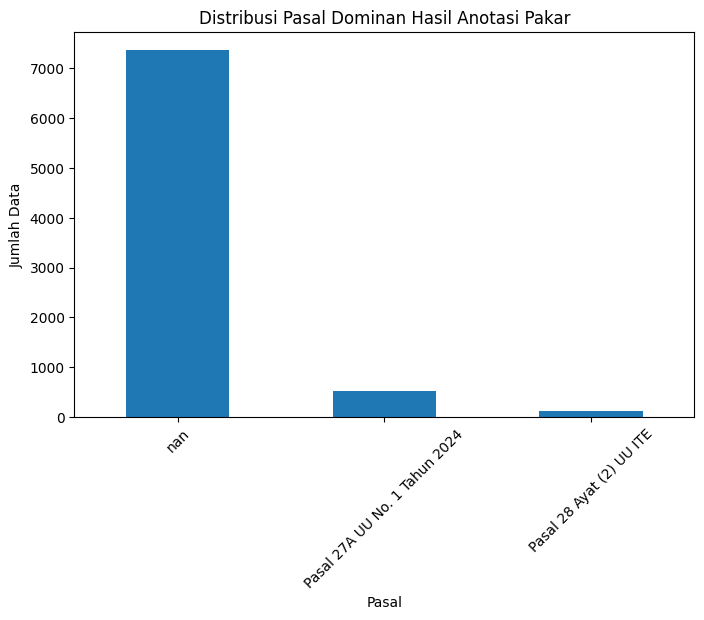

In [ ]:
plt.figure(figsize=(8,5))

df["Pasal Dominan"].value_counts(dropna=False).plot(kind="bar")

plt.title("Distribusi Pasal Dominan Hasil Anotasi Pakar")
plt.xlabel("Pasal")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=45)

plt.show()

11 — Hubungan Kelas dengan Pasal Dominan

In [ ]:
pd.crosstab(
    df["Kode Label"],
    df["Pasal Dominan"],
    dropna=False)

Pasal Dominan,Pasal 27A UU No. 1 Tahun 2024,Pasal 28 Ayat (2) UU ITE,NaN
Kode Label,,,
C0,2,0,2224
C1,1,0,3011
C2,5,0,1446
C3,522,112,129
C4,0,0,545
NaN,0,0,3


12 — Pemeriksaan Duplikasi Komentar

In [ ]:
jumlah_duplikat = (
    df["Komentar"]
    .duplicated()
    .sum())

print("Jumlah komentar duplikat:",jumlah_duplikat)

Jumlah komentar duplikat: 0


In [ ]:
df[df["Komentar"].duplicated(keep=False)]

,No,Komentar,Label Awal,Label Pakar,Pasal Dominan,Catatan,Unnamed: 6,Kode Label


13 — Analisis Panjang Komentar

In [ ]:
df["jumlah_kata"] = (
    df["Komentar"]
    .astype(str)
    .apply(lambda x: len(x.split())))

df["jumlah_karakter"] = (
    df["Komentar"]
    .astype(str)
    .apply(len))

14 - Statistik Panjang Komentar Keseluruhan

In [ ]:
df[["jumlah_kata","jumlah_karakter"]].describe()

,jumlah_kata,jumlah_karakter
count,8000.000000,8000.000000
mean,26.481000,175.043125
std,38.570288,263.042130
min,1.000000,1.000000
25%,9.000000,58.000000
50%,17.000000,109.000000
75%,30.000000,198.000000
max,882.000000,6297.000000


15 - Panjang Komentar Per Kelas (Within Class)

In [ ]:
panjang_per_kelas = (
    df.groupby("Kode Label")
    ["jumlah_kata"]
    .agg(
        Jumlah_Data="count",
        Rata_rata_Kata="mean",
        Median_Kata="median",
        Minimum_Kata="min",
        Maksimum_Kata="max"
    ).reset_index())

panjang_per_kelas

,Kode Label,Jumlah_Data,Rata_rata_Kata,Median_Kata,Minimum_Kata,Maksimum_Kata
0,C0,2226,21.769542,14.0,1,882
1,C1,3012,31.454515,21.0,1,463
2,C2,1451,22.639559,15.0,1,417
3,C3,763,38.209699,22.0,1,709
4,C4,545,12.157798,8.0,1,113


16 - Perbandingan Panjang Komentar Antar Kelas (Inter Class)

In [ ]:
perbandingan_kelas = (
    df.groupby("Kode Label")
    ["jumlah_kata"]
    .mean()
    .reset_index())

perbandingan_kelas.columns = ["Kode Label","Rata-rata Jumlah Kata"]
perbandingan_kelas

,Kode Label,Rata-rata Jumlah Kata
0,C0,21.769542
1,C1,31.454515
2,C2,22.639559
3,C3,38.209699
4,C4,12.157798


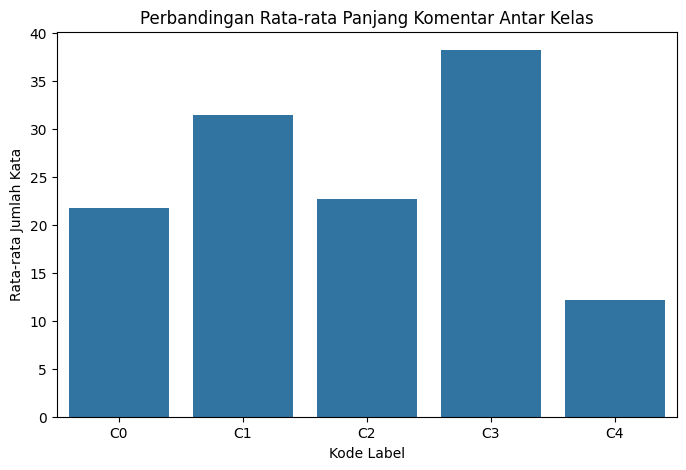

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=perbandingan_kelas,
    x="Kode Label",
    y="Rata-rata Jumlah Kata")

plt.title("Perbandingan Rata-rata Panjang Komentar Antar Kelas")
plt.xlabel("Kode Label")
plt.ylabel("Rata-rata Jumlah Kata")

plt.show()

##Tambahan C4

17 — Import Dataset Raw Crawling

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()
df_raw = pd.read_csv("dataset_raw.csv")
df_raw.head()

Saving dataset_raw.csv to dataset_raw.csv


,kategori,subtopik,judul_video,channel,comment_id,comment_text,likes,published_time
0,Politik,Politik Identitas,Keturunan PKI dan TNI,Tribun Medan TV,UgzXfW6Hdt5fRtQoDZ94AaABAg,Memang benar menggunakan dasar hukum tapi ke...,2.5k,4 years ago
1,Politik,Politik Identitas,Keturunan PKI dan TNI,Tribun Medan TV,UgzJsTcKetnmcGxyVat4AaABAg,"Semoga TNI tetap dijalurnya, dengan tanpa disu...",620,4 years ago
2,Politik,Politik Identitas,Keturunan PKI dan TNI,Tribun Medan TV,UgzXJiAW_qAHvyS_x6x4AaABAg,Bisa tidur tenang punya panglima sehebat belia...,22,3 years ago
3,Politik,Politik Identitas,Keturunan PKI dan TNI,Tribun Medan TV,UgwPKadCZ7CQ6Tj3X2d4AaABAg,aku dari malaysia aja..bangga lihat bapak jend...,43,3 years ago
4,Politik,Politik Identitas,Keturunan PKI dan TNI,Tribun Medan TV,UgzhKLSX-ep-QeoRygV4AaABAg,Semoga TNI tetap konsisten membela NKRI...Dan ...,609,4 years ago


18 — Melihat Struktur Dataset Raw

In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9917 entries, 0 to 9916
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   kategori        9917 non-null   object
 1   subtopik        9917 non-null   object
 2   judul_video     9917 non-null   object
 3   channel         9917 non-null   object
 4   comment_id      9917 non-null   object
 5   comment_text    9917 non-null   object
 6   likes           9917 non-null   object
 7   published_time  9917 non-null   object
dtypes: object(8)
memory usage: 619.9+ KB


In [ ]:
df_raw.shape

(9917, 8)

19 — Ambil Data Referensi C4 dari Pakar

In [ ]:
df_c4 = df[df["Kode Label"] == "C4"].copy()
print("Jumlah data C4 awal:",len(df_c4))

Jumlah data C4 awal: 545


20 — Melihat Pola C4 Berdasarkan Catatan Pakar

In [ ]:
df_c4[["Komentar","Catatan"]].sample(20, random_state=42)

,Komentar,Catatan
3470,Pancet ae,makna komentar belum bisa dipastikan tanpa men...
721,Susupi ? Cari di mana anak baru tamat SMA angg...,Belum dapat ditentukan—konteks tidak cukup. Ko...
3870,Mungkin yg nanya bini nya ilang d bawa angin 😅😅😅,makna komentar belum bisa dipastikan tanpa men...
860,Tandai partainya,Belum dapat ditentukan—konteks tidak cukup. Te...
5702,Awas kau di polisikan,Kalimat ancaman tanpa konteks yang memadai.
2494,Yg rusak maknya,makna komentar belum bisa dipastikan tanpa men...
2174,cerdas apanya...ngeyel gitu,"komentar bernada menyalahkan atau kecewa, namu..."
2923,@nasakom2752 🐖💨 PKI,belum terlihat dengan pasti siapa atau apa yan...
6500,Dosa kmi sbg muslim kaya gitu,Makna komentar tidak jelas.
4580,Dibuku jwp hanya 49.....koq mau bikin buku?per...,makna yang dimaksud penulis masih samar dan ti...


21 — Membersihkan Teks Komentar

In [ ]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(
        r"\s+",
        " ",
        text)
    return text.strip()

In [ ]:
df["clean_comment"] = (
    df["Komentar"]
    .apply(clean_text))

df_raw["clean_comment"] = (
    df_raw["comment_text"]
    .apply(clean_text))

22 — Menghapus Komentar Raw yang Sudah Ada di Dataset Pakar

In [ ]:
existing_comments = set(df["clean_comment"])

df_candidate = df_raw[
    ~df_raw["clean_comment"]
    .isin(existing_comments)].copy()

print("Jumlah kandidat baru:",len(df_candidate))

Jumlah kandidat baru: 8076


23 — Menghitung Panjang Kandidat Komentar

In [ ]:
df_candidate["jumlah_kata"] = (
    df_candidate["comment_text"]
    .astype(str)
    .apply(lambda x: len(x.split())))

24 — Seleksi Kandidat Tambahan C4

In [ ]:
df_c4_candidate = df_candidate[df_candidate["jumlah_kata"] <= 20].copy()
print("Jumlah kandidat C4:",len(df_c4_candidate))

Jumlah kandidat C4: 6498


25 — Ambil 218 Data Tambahan

In [ ]:
tambahan_c4 = (df_c4_candidate.sample(n=218,random_state=42))
tambahan_c4.head()

,kategori,subtopik,judul_video,channel,comment_id,comment_text,likes,published_time,clean_comment,jumlah_kata
8537,Politik,Pilpres & Kandidat Politik,Kandidat Terkuat 2029,Newlitics dan Helmy Yahya Bicara,Ugxpq5W7_7N8t_sblzp4AaABAg.AV3AnObbI1iAV40D_i3E5O,Maksa banget 😂😂😂,0,1 month ago,maksa banget 😂😂😂,3
2734,Politik,Analisis Politik,Prabowo Bisa Terjungkal,Forum Keadilan TV,UgwkZL1ltiWDZRLDRb14AaABAg.AFUSD9Un5-YAFUaVGQZI1q,Satpam merangkap baby suster,7,1 year ago,satpam merangkap baby suster,4
8940,Politik,Politik Identitas,Ijazah Jokowi Dianalisis Palsu,Liputan6,Ugwd4cQMpdauJPFpmN54AaABAg.AM7faD1JE-JARC0VLbvONh,​ @MomDadJacobslife Biar fair juga jika palsu ...,5,4 months ago,​ @momdadjacobslife biar fair juga jika palsu ...,11
2827,Politik,Analisis Politik,Prabowo Bisa Terjungkal,Forum Keadilan TV,UgxMECyv_Ku9YhbCTNp4AaABAg,Nah ini masuk akal.....,0,2 weeks ago,nah ini masuk akal.....,4
8720,Politik,Pilpres & Kandidat Politik,Kandidat Terkuat 2029,Newlitics dan Helmy Yahya Bicara,UgyZ9JVOI0oRP73r5_x4AaABAg,Jawa tengah dukung KDM❤,0,3 weeks ago,jawa tengah dukung kdm❤,4


26 — Membentuk Format Dataset Tambahan C4

In [ ]:
tambahan_c4_final = pd.DataFrame({
    "Komentar":tambahan_c4["comment_text"],
    "Label Awal":"Ambigu atau konteks tidak cukup",
    "Label Pakar":"Ambigu atau konteks tidak cukup",
    "Pasal Dominan":None,
    "Catatan":"Data tambahan kelas C4 berdasarkan karakteristik komentar ambigu",
    "Kode Label":"C4"})

tambahan_c4_final.head()

,Komentar,Label Awal,Label Pakar,Pasal Dominan,Catatan,Kode Label
8537,Maksa banget 😂😂😂,Ambigu atau konteks tidak cukup,Ambigu atau konteks tidak cukup,None,Data tambahan kelas C4 berdasarkan karakterist...,C4
2734,Satpam merangkap baby suster,Ambigu atau konteks tidak cukup,Ambigu atau konteks tidak cukup,None,Data tambahan kelas C4 berdasarkan karakterist...,C4
8940,​ @MomDadJacobslife Biar fair juga jika palsu ...,Ambigu atau konteks tidak cukup,Ambigu atau konteks tidak cukup,None,Data tambahan kelas C4 berdasarkan karakterist...,C4
2827,Nah ini masuk akal.....,Ambigu atau konteks tidak cukup,Ambigu atau konteks tidak cukup,None,Data tambahan kelas C4 berdasarkan karakterist...,C4
8720,Jawa tengah dukung KDM❤,Ambigu atau konteks tidak cukup,Ambigu atau konteks tidak cukup,None,Data tambahan kelas C4 berdasarkan karakterist...,C4


27 — Simpan Sebelum Digabung

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
tambahan_c4_final.to_csv("/content/drive/MyDrive/Bimbingan_27-08/tambahan_C4_sebelum_gabung.csv",index=False)

print("Berhasil disimpan")

Berhasil disimpan


28 — Cek Duplikasi dengan Dataset Pakar

In [ ]:
tambahan_c4_final["clean_comment"] = (tambahan_c4_final["Komentar"].apply(clean_text))
duplikat = tambahan_c4_final[
    tambahan_c4_final["clean_comment"]
    .isin(df["clean_comment"])]

print("Jumlah duplikasi:",len(duplikat))

Jumlah duplikasi: 0


29 — Cek Konflik Label

In [ ]:
cek_label = df[
    df["clean_comment"]
    .isin(tambahan_c4_final["clean_comment"])]

cek_label[["Komentar", "Label Pakar", "Kode Label"]]

,Komentar,Label Pakar,Kode Label


30 — Gabungkan Jika Sudah Aman

In [ ]:
df_dengan_c4_tambahan = pd.concat([df, tambahan_c4_final], ignore_index=True)
df_dengan_c4_tambahan["Kode Label"].value_counts()

,count
Kode Label,
C1,3012
C0,2226
C2,1451
C4,763
C3,763


32 — Simpan Dataset Sebelum Balancing

In [ ]:
df_dengan_c4_tambahan.to_csv("/content/drive/MyDrive/Bimbingan_27-08/dataset_setelah_tambah_C4_sebelum_balancing.csv", index=False)

print("Dataset berhasil disimpan")

Dataset berhasil disimpan


33 — Cek Jumlah Total Dataset

In [ ]:
print("Jumlah data sebelum balancing:",len(df_dengan_c4_tambahan))

Jumlah data sebelum balancing: 8218


34 — EDA Lanjutan

 EDA Lanjutan — Analisis Karakteristik C2, C3, dan C4

Analisis lanjutan dilakukan setelah penambahan data kelas C4 untuk melihat karakteristik dan kedekatan antarkelas, khususnya C2–C3 dan C3–C4. Analisis ini digunakan untuk menginvestigasi kemungkinan kemiripan karakteristik teks yang dapat menyebabkan kesalahan klasifikasi antarkelas.

35 — Menyiapkan Dataset Setelah Penambahan C4

In [ ]:
df_analisis = df_dengan_c4_tambahan.copy()

print("Jumlah data:")
print(len(df_analisis))
print("\nDistribusi kelas:")
print(df_analisis["Kode Label"].value_counts().sort_index())

Jumlah data:
8218

Distribusi kelas:
Kode Label
C0    2226
C1    3012
C2    1451
C3     763
C4     763
Name: count, dtype: int64


36 — Distribusi C2, C3, C4 Setelah Penambahan C4

In [ ]:
kelas_fokus = ["C2", "C3", "C4"]

distribusi_fokus = (
    df_analisis[
        df_analisis["Kode Label"].isin(kelas_fokus)
    ]["Kode Label"]
    .value_counts()
    .reindex(kelas_fokus))

display(distribusi_fokus)

,count
Kode Label,
C2,1451
C3,763
C4,763


37 — Menyiapkan Teks untuk Analisis

In [ ]:
df_c234 = df_analisis[df_analisis["Kode Label"].isin(["C2", "C3", "C4"])].copy()
df_c234["Komentar"] = (df_c234["Komentar"].fillna("").astype(str))

print("Jumlah data yang dianalisis:")
print(df_c234["Kode Label"].value_counts().sort_index())

Jumlah data yang dianalisis:
Kode Label
C2    1451
C3     763
C4     763
Name: count, dtype: int64


38 — Frekuensi Kata C2, C3, C4

In [ ]:
from collections import Counter
import re

def tokenisasi_eda(teks):
    return re.findall(r'\b\w+\b', teks.lower())

frekuensi_kata = {}
for kelas in ["C2", "C3", "C4"]:
    semua_kata = []
    teks_kelas = df_c234.loc[
        df_c234["Kode Label"] == kelas,"Komentar"]
    for teks in teks_kelas:
        semua_kata.extend(tokenisasi_eda(teks))
    frekuensi_kata[kelas] = Counter(semua_kata)

for kelas in ["C2", "C3", "C4"]:
    print(f"\n===== {kelas} =====")
    for kata, jumlah in frekuensi_kata[kelas].most_common(20):
        print(f"{kata:<20} {jumlah}")


===== C2 =====
dan                  637
yg                   610
di                   542
ini                  362
yang                 316
itu                  313
partai               273
rakyat               232
orang                222
ada                  215
tidak                203
dari                 186
bisa                 183
pak                  180
nya                  169
negara               161
jadi                 161
jokowi               149
koruptor             147
indonesia            141

===== C3 =====
yg                   640
dan                  607
di                   490
itu                  320
ini                  305
yang                 253
negara               233
dari                 223
jokowi               196
orang                179
pki                  176
indonesia            176
tidak                167
jadi                 158
nya                  153
rakyat               150
ada                  150
bisa                 146
presiden          

39 — Visualisasi Kata Dominan

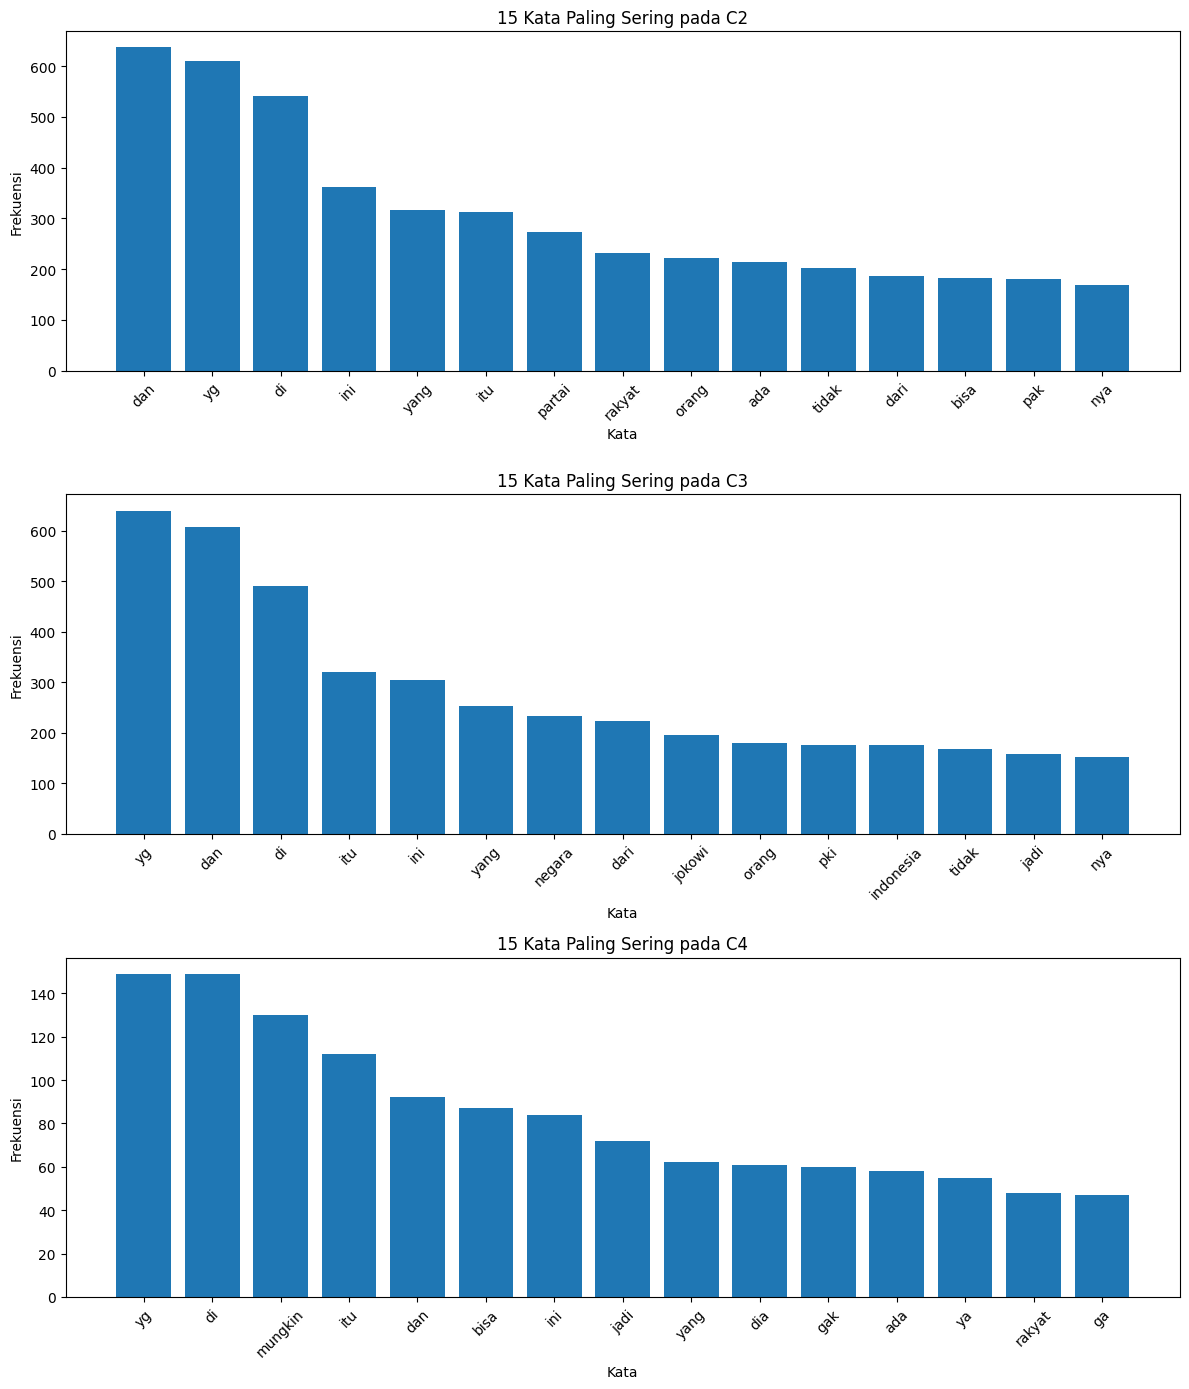

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(12, 14))
for ax, kelas in zip(axes, ["C2", "C3", "C4"]):
    data = frekuensi_kata[kelas].most_common(15)
    kata = [x[0] for x in data]
    jumlah = [x[1] for x in data]

    ax.bar(kata, jumlah)
    ax.set_title(f"15 Kata Paling Sering pada {kelas}")
    ax.set_xlabel("Kata")
    ax.set_ylabel("Frekuensi")
    ax.tick_params(axis="x",rotation=45)

plt.tight_layout()
plt.show()

40 — Kata Bersama C2 dan C3

In [ ]:
kata_c2 = set(frekuensi_kata["C2"].keys())
kata_c3 = set(frekuensi_kata["C3"].keys())
kata_bersama_c2_c3 = (kata_c2.intersection(kata_c3))

print("Jumlah kata unik C2:",len(kata_c2))
print("Jumlah kata unik C3:",len(kata_c3))
print("Jumlah kata yang sama:",len(kata_bersama_c2_c3))
print("\n20 kata bersama paling dominan:")

ranking_c2_c3 = sorted(
    kata_bersama_c2_c3,
    key=lambda kata:
        frekuensi_kata["C2"][kata]+frekuensi_kata["C3"][kata],
    reverse=True)

for kata in ranking_c2_c3[:20]:
    print(
        f"{kata:<20} "
        f"C2={frekuensi_kata['C2'][kata]:<5} "
        f"C3={frekuensi_kata['C3'][kata]}")

Jumlah kata unik C2: 7371
Jumlah kata unik C3: 6572
Jumlah kata yang sama: 3188

20 kata bersama paling dominan:
yg                   C2=610   C3=640
dan                  C2=637   C3=607
di                   C2=542   C3=490
ini                  C2=362   C3=305
itu                  C2=313   C3=320
yang                 C2=316   C3=253
dari                 C2=186   C3=223
orang                C2=222   C3=179
negara               C2=161   C3=233
rakyat               C2=232   C3=150
tidak                C2=203   C3=167
ada                  C2=215   C3=150
jokowi               C2=149   C3=196
partai               C2=273   C3=63
bisa                 C2=183   C3=146
nya                  C2=169   C3=153
jadi                 C2=161   C3=158
indonesia            C2=141   C3=176
pak                  C2=180   C3=95
pki                  C2=66    C3=176


41 — Kata Bersama C3 dan C4

In [ ]:
kata_c4 = set(frekuensi_kata["C4"].keys())
kata_bersama_c3_c4 = (kata_c3.intersection(kata_c4))

print("Jumlah kata unik C3:", len(kata_c3))
print("Jumlah kata unik C4:", len(kata_c4))
print("Jumlah kata yang sama:", len(kata_bersama_c3_c4))
print("\n20 kata bersama paling dominan:")

ranking_c3_c4 = sorted(
    kata_bersama_c3_c4,
    key=lambda kata:
        frekuensi_kata["C3"][kata]+frekuensi_kata["C4"][kata],
    reverse=True)

for kata in ranking_c3_c4[:20]:
    print(
        f"{kata:<20} "
        f"C3={frekuensi_kata['C3'][kata]:<5} "
        f"C4={frekuensi_kata['C4'][kata]}")

Jumlah kata unik C3: 6572
Jumlah kata unik C4: 3162
Jumlah kata yang sama: 1742

20 kata bersama paling dominan:
yg                   C3=640   C4=149
dan                  C3=607   C4=92
di                   C3=490   C4=149
itu                  C3=320   C4=112
ini                  C3=305   C4=84
yang                 C3=253   C4=62
negara               C3=233   C4=28
dari                 C3=223   C4=32
bisa                 C3=146   C4=87
jadi                 C3=158   C4=72
jokowi               C3=196   C4=24
orang                C3=179   C4=32
tidak                C3=167   C4=42
ada                  C3=150   C4=58
indonesia            C3=176   C4=25
nya                  C3=153   C4=46
rakyat               C3=150   C4=48
pki                  C3=176   C4=18
mungkin              C3=44    C4=130
dia                  C3=110   C4=61


Ringkasan Analisis Kemiripan Kosakata

Hasil analisis kata bersama digunakan untuk membandingkan karakteristik kosakata antara C2–C3 dan C3–C4. Analisis ini bersifat eksploratif untuk melihat kemungkinan adanya kemiripan karakteristik bahasa antarkelas yang dapat menjadi salah satu pertimbangan dalam memahami kesalahan klasifikasi.

42 — Ringkasan Kata Bersama

In [ ]:
ringkasan_kemiripan_kata = pd.DataFrame({
    "Pasangan Kelas": ["C2-C3", "C3-C4"],
    "Jumlah Kata Unik Kelas Pertama": [len(kata_c2), len(kata_c3)],
    "Jumlah Kata Unik Kelas Kedua": [len(kata_c3), len(kata_c4)],
    "Jumlah Kata Bersama": [len(kata_bersama_c2_c3), len(kata_bersama_c3_c4)]
})

display(ringkasan_kemiripan_kata)

,Pasangan Kelas,Jumlah Kata Unik Kelas Pertama,Jumlah Kata Unik Kelas Kedua,Jumlah Kata Bersama
0,C2-C3,7371,6572,3188
1,C3-C4,6572,3162,1742


Perbandingan jumlah kata bersama divisualisasikan untuk melihat pasangan kelas yang memiliki lebih banyak kosakata yang sama.

43 — Visualisasi Kata Bersama

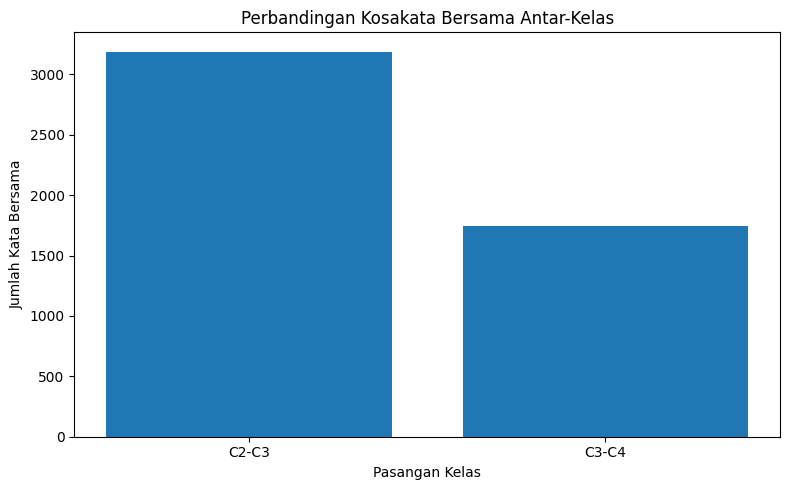

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(ringkasan_kemiripan_kata["Pasangan Kelas"], ringkasan_kemiripan_kata["Jumlah Kata Bersama"])

plt.xlabel("Pasangan Kelas")
plt.ylabel("Jumlah Kata Bersama")
plt.title("Perbandingan Kosakata Bersama Antar-Kelas")

plt.tight_layout()
plt.show()

Interpretasi Awal

Jumlah kata bersama digunakan sebagai indikator eksploratif untuk melihat kemiripan kosakata antar kelas. Hasil ini tidak digunakan untuk menentukan perubahan label, tetapi sebagai dasar untuk memahami karakteristik teks pada kelas yang berpotensi sulit dibedakan.